In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

In [2]:
def duplicate_rows(df):
    return df[df.duplicated()]

def rows_with_missing_values(df):
    return df[df.isnull().any(axis=1)]

def numerical_columns(df):
    return df.select_dtypes(include=['float64']).columns

def categorical_columns(df):
    return df.select_dtypes(include=['object']).columns

In [3]:
df = pd.read_csv('ObesityDataSet.csv')
df.head(10)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,NaN,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II
5,Male,29.0,1.62,53.0,no,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Automobile,Normal_Weight
6,Female,23.0,1.50,55.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,0.0,Sometimes,Motorbike,Normal_Weight
7,Male,22.0,1.64,53.0,no,no,2.0,3.0,Sometimes,no,2.0,no,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
8,Male,24.0,1.78,64.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Frequently,Public_Transportation,Normal_Weight
9,Male,22.0,1.72,68.0,NaN,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2110 non-null   float64
 2   Height                          2107 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2110 non-null   object 
 5   FAVC                            2109 non-null   object 
 6   FCVC                            2110 non-null   float64
 7   NCP                             2110 non-null   float64
 8   CAEC                            2110 non-null   object 
 9   SMOKE                           2110 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2110 non-null   object 
 12  FAF                             21

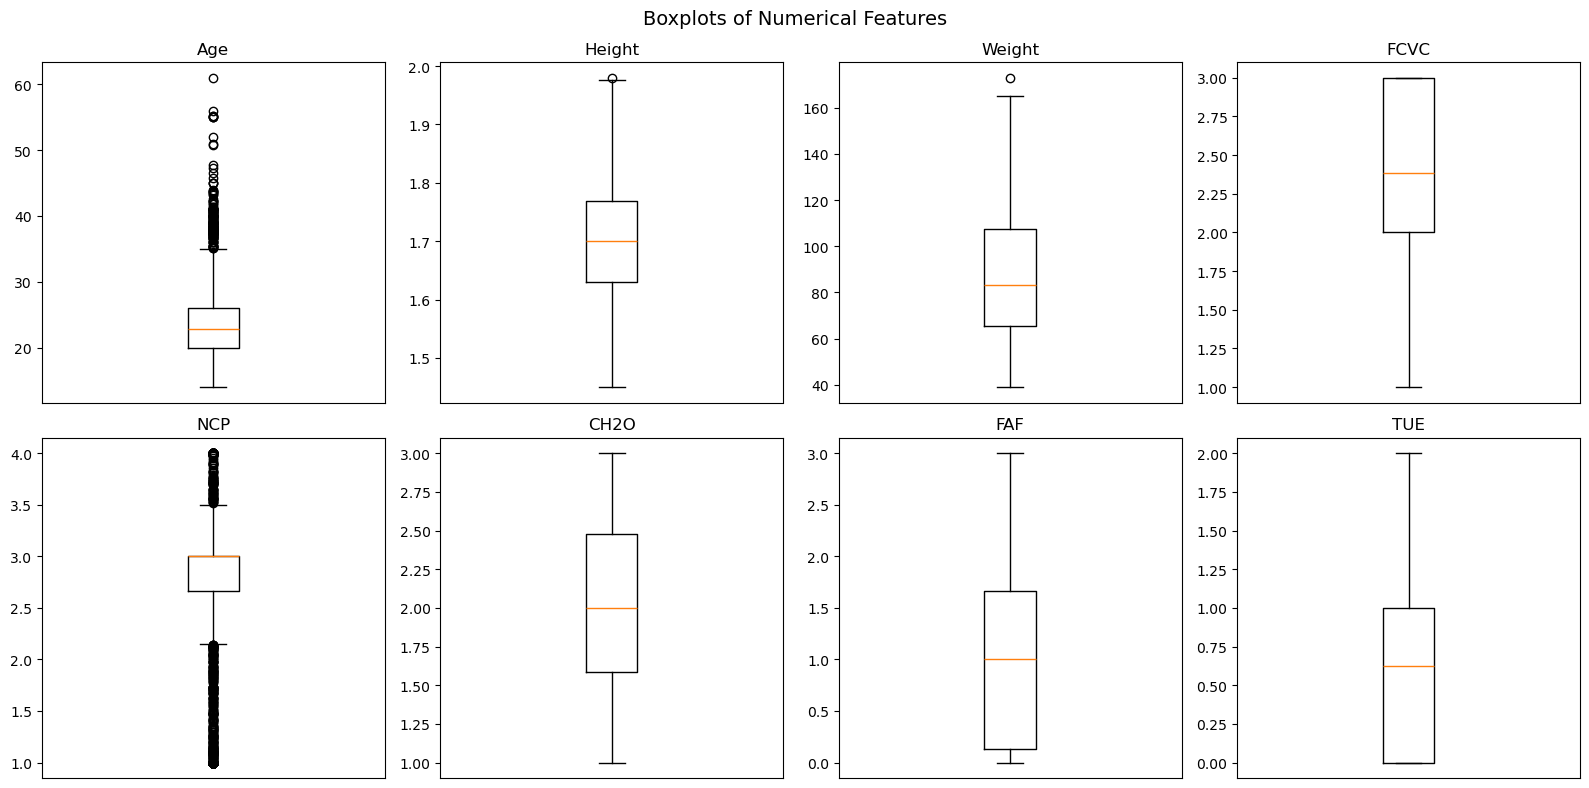

In [5]:
num_cols = df.select_dtypes(include='float64').columns
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, num_cols):
    ax.boxplot(df[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])

plt.suptitle('Boxplots of Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2110.0,24.314170,6.347063,14.00,19.946718,22.783646,26.000000,61.00
Height,2107.0,1.701804,0.093297,1.45,1.630000,1.700627,1.768536,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2110.0,2.419242,0.533975,1.00,2.000000,2.386464,3.000000,3.00
NCP,2110.0,2.686427,0.777357,1.00,2.660328,3.000000,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,1.584812,2.000000,2.477420,3.00
FAF,2109.0,1.009833,0.849607,0.00,0.127425,1.000000,1.666390,3.00
TUE,2110.0,0.657230,0.608370,0.00,0.000000,0.625350,1.000000,2.00


In [7]:
df.describe(include='object').T

,count,unique,top,freq
Gender,2111,2,Male,1068
family_history_with_overweight,2110,2,yes,1725
FAVC,2109,2,yes,1865
CAEC,2110,4,Sometimes,1764
SMOKE,2110,2,no,2066
SCC,2110,2,no,2015
CALC,2108,4,Sometimes,1398
MTRANS,2109,5,Public_Transportation,1578
NObeyesdad,2111,7,Obesity_Type_I,351


In [8]:
df.isnull().sum()

Gender                            0
Age                               1
Height                            4
Weight                            0
family_history_with_overweight    1
FAVC                              2
FCVC                              1
NCP                               1
CAEC                              1
SMOKE                             1
CH2O                              0
SCC                               1
FAF                               2
TUE                               1
CALC                              3
MTRANS                            2
NObeyesdad                        0
dtype: int64

In [9]:
rows_with_missing_values(df)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,NaN,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
9,Male,22.0,1.72,68.0,NaN,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
19,Female,23.0,1.65,70.0,yes,no,NaN,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
21,Female,52.0,1.69,87.0,yes,yes,3.0,1.0,Sometimes,yes,2.0,no,NaN,0.0,no,Automobile,Obesity_Type_I
22,Female,22.0,1.65,60.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,0.0,NaN,Automobile,Normal_Weight
31,Female,31.0,1.58,68.0,yes,NaN,2.0,1.0,Sometimes,no,1.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II
33,Male,39.0,1.79,90.0,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,NaN,Overweight_Level_II
36,Female,22.0,NaN,49.0,no,yes,2.0,3.0,Sometimes,no,1.0,yes,2.0,0.0,no,Walking,Normal_Weight
71,Female,22.0,1.67,50.0,yes,no,3.0,3.0,no,no,3.0,NaN,2.0,1.0,Sometimes,Public_Transportation,Insufficient_Weight
77,Female,24.0,1.70,80.0,yes,yes,2.0,3.0,NaN,no,3.0,no,0.0,0.0,no,Public_Transportation,Overweight_Level_II


In [10]:
df.dropna(inplace=True)

In [11]:
duplicate_rows(df)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
106,Female,25.0,1.57,55.0,no,yes,2.0,1.0,Sometimes,no,2.0,no,2.0,0.0,Sometimes,Public_Transportation,Normal_Weight
174,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
179,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
184,Male,21.0,1.62,70.0,no,yes,2.0,1.0,no,no,3.0,no,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_I
209,Female,22.0,1.69,65.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight
309,Female,16.0,1.66,58.0,no,no,2.0,1.0,Sometimes,no,1.0,no,0.0,1.0,no,Walking,Normal_Weight
460,Female,18.0,1.62,55.0,yes,yes,2.0,3.0,Frequently,no,1.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight
467,Male,22.0,1.74,75.0,yes,yes,3.0,3.0,Frequently,no,1.0,no,1.0,0.0,no,Automobile,Normal_Weight
496,Male,18.0,1.72,53.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight
527,Female,21.0,1.52,42.0,no,yes,3.0,1.0,Frequently,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation,Insufficient_Weight


In [12]:
df.drop_duplicates(keep='first', inplace=True)
df.shape

(2068, 17)

In [13]:
for col in categorical_columns(df):
    print(f"Unique values in {col}: {df[col].unique()}")

Unique values in Gender: ['Female' 'Male']
Unique values in family_history_with_overweight: ['yes' 'no']
Unique values in FAVC: ['no' 'yes']
Unique values in CAEC: ['Sometimes' 'Frequently' 'Always' 'no']
Unique values in SMOKE: ['yes' 'no']
Unique values in SCC: ['yes' 'no']
Unique values in CALC: ['Sometimes' 'Frequently' 'no' 'Always']
Unique values in MTRANS: ['Public_Transportation' 'Walking' 'Automobile' 'Motorbike' 'Bike']
Unique values in NObeyesdad: ['Normal_Weight' 'Overweight_Level_I' 'Overweight_Level_II'
 'Obesity_Type_I' 'Insufficient_Weight' 'Obesity_Type_II'
 'Obesity_Type_III']


In [14]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['family_history_with_overweight'] = df['family_history_with_overweight'].map({'no': 0, 'yes': 1})
df['FAVC'] = df['FAVC'].map({'no': 0, 'yes': 1})
df['SMOKE'] = df['SMOKE'].map({'no': 0, 'yes': 1})
df['SCC'] = df['SCC'].map({'no': 0, 'yes': 1})
df['CAEC'] = df['CAEC'].map({'no' : 0 , 'Sometimes' : 1, 'Frequently' : 2, 'Always' : 3})
df['CALC'] = df['CALC'].map({'no' : 0 , 'Sometimes' : 1, 'Frequently' : 2, 'Always' : 3})
df['NObeyesdad'] = df['NObeyesdad'].map({'Insufficient_Weight': 0, 'Normal_Weight' : 1, 'Overweight_Level_I' : 2,
                                             'Overweight_Level_II' : 3, 'Obesity_Type_I' : 4, 'Obesity_Type_II' : 5,
                                             'Obesity_Type_III' : 6})

In [15]:
df2 = pd.get_dummies(df)

In [16]:
X = df2.drop(columns=['NObeyesdad'])
y = df2['NObeyesdad']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42, stratify=y)

In [17]:
model = DecisionTreeClassifier(random_state=52)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98        53
           1       0.96      0.89      0.92        54
           2       0.85      0.96      0.91        55
           3       0.94      0.86      0.90        57
           4       0.90      0.94      0.92        70
           5       0.95      0.93      0.94        60
           6       0.98      0.98      0.98        65

    accuracy                           0.94       414
   macro avg       0.94      0.94      0.94       414
weighted avg       0.94      0.94      0.94       414



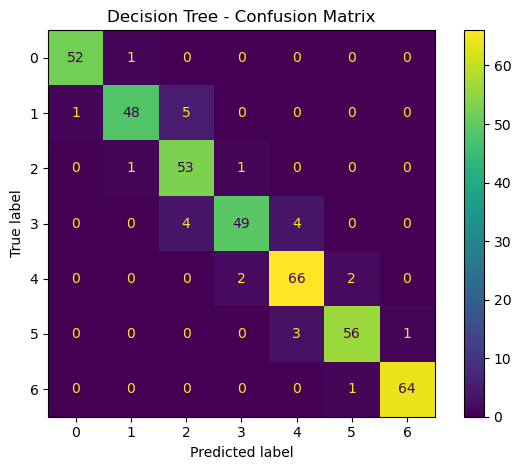

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Decision Tree - Confusion Matrix')
plt.tight_layout()
plt.show()

In [19]:
model2 = RandomForestClassifier(random_state=52)
model2.fit(X_train, y_train)
y_pred = model2.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        53
           1       0.81      0.96      0.88        54
           2       0.96      0.87      0.91        55
           3       0.95      0.93      0.94        57
           4       1.00      0.97      0.99        70
           5       1.00      0.98      0.99        60
           6       0.98      0.98      0.98        65

    accuracy                           0.96       414
   macro avg       0.96      0.96      0.96       414
weighted avg       0.96      0.96      0.96       414



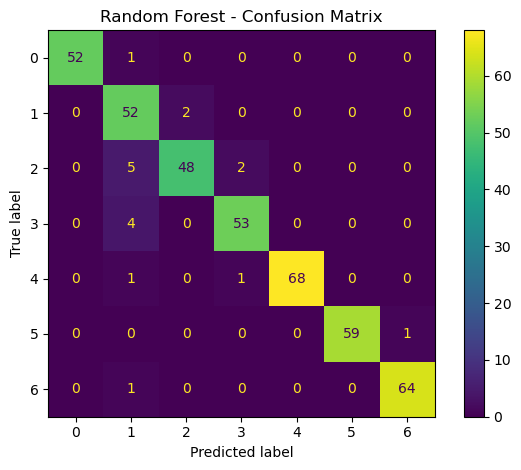

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title('Random Forest - Confusion Matrix')
plt.tight_layout()
plt.show()